In [1]:
%pip -q install torchmetrics torch-fidelity

In [ ]:
import os, io, json, time, random, shutil, zipfile, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid, save_image

# ------------------------------- configuration -------------------------------
SEED = 42
TRAIN_RATIO = 0.80
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 300                 # 12 steps/epoch -> 3,600 optimiser steps per model
LATENT_DIM = 128
LR_GAN = 2e-4                # DCGAN paper settings (Adam, beta1 = 0.5)
LR_VAE = 1e-3
BETA_KL = 1.0
USE_DIFFAUGMENT = True       
REAL_LABEL = 0.9             # one-sided label smoothing for D (1.0 = off)
NEAR_DUP_HAMMING = 6         # dHash distance at or below which two images are treated as near-duplicates
N_EVAL_SAMPLES = 1000        # generated images per model for KID/FID
PROGRESS_EVERY = 25          # save a fixed-noise grid every N epochs
VAE_EVAL_EVERY = 10

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

WORK = Path("/content") if Path("/content").exists() else Path.cwd()
RESULTS = WORK / "cosmetics_model_results"
if RESULTS.exists(): shutil.rmtree(RESULTS)
(RESULTS / "progress").mkdir(parents=True)

Device: cuda | NVIDIA A100-SXM4-40GB


In [ ]:
ZIP_PATH = None   
if ZIP_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    zips = [n for n in uploaded if n.lower().endswith(".zip")]
    if not zips:
        raise ValueError("Please upload a ZIP file.")
    ZIP_PATH = WORK / zips[0]

extract_dir = WORK / "beauty_api_extracted"
if extract_dir.exists(): shutil.rmtree(extract_dir)
extract_dir.mkdir(parents=True)
with zipfile.ZipFile(ZIP_PATH) as zf:                    
    for m in zf.infolist():
        dest = (extract_dir / m.filename).resolve()
        if dest != extract_dir.resolve() and extract_dir.resolve() not in dest.parents:
            continue
        if m.is_dir():
            dest.mkdir(parents=True, exist_ok=True)
        else:
            dest.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(m) as s, open(dest, "wb") as d: shutil.copyfileobj(s, d)
print("Extracted to", extract_dir)

Saving the-beauty-api-sample-dataset.zip to the-beauty-api-sample-dataset.zip
Extracted to /content/beauty_api_extracted


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
candidates = sorted(p for p in extract_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def dhash(img, size=8):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).flatten())

unique, hashes, seen, bad, exact_dups = [], [], set(), [], 0
for p in tqdm(candidates, desc="Validating"):
    try:
        with Image.open(p) as im: im.verify()
        digest = hashlib.sha256(p.read_bytes()).hexdigest()
        if digest in seen:
            exact_dups += 1; continue
        seen.add(digest)
        with Image.open(p) as im: hashes.append(dhash(im))
        unique.append(p)
    except (UnidentifiedImageError, OSError, ValueError):
        bad.append(str(p))
print(f"Files: {len(candidates)} | valid unique: {len(unique)} | exact duplicates: {exact_dups} | invalid: {len(bad)}")

# near-duplicate groups by leader clustering: an image joins a group only if it is within the threshold
# of that group's first image, so chains of small differences cannot merge unrelated images.
H = np.unpackbits(np.stack(hashes), axis=1).astype(bool)
dist = (H[:, None, :] != H[None, :, :]).sum(-1)
pairs = np.argwhere(np.triu(dist <= NEAR_DUP_HAMMING, k=1))
leaders, groups = [], {}
for i in range(len(unique)):
    close = [l for l in leaders if dist[i, l] <= NEAR_DUP_HAMMING]
    if close:
        groups[min(close, key=lambda l: dist[i, l])].append(i)
    else:
        leaders.append(i); groups[i] = [i]
largest = max(len(g) for g in groups.values())
if largest > 0.05 * len(unique):
    print(f"WARNING: largest near-duplicate group has {largest} images - consider lowering NEAR_DUP_HAMMING")
print(f"Near-duplicate pairs: {len(pairs)} | groups: {len(groups)} | largest group: {largest}")

Validating:   0%|          | 0/1000 [00:00<?, ?it/s]

Files: 1000 | valid unique: 1000 | exact duplicates: 0 | invalid: 0
Near-duplicate pairs: 129 | groups: 944 | largest group: 6


In [5]:
# group-aware split: near-duplicates always land on the same side
group_list = list(groups.values())
random.Random(SEED).shuffle(group_list)
n_train_target = int(len(unique) * TRAIN_RATIO)
train_idx, test_idx = [], []
for g in group_list:
    (train_idx if len(train_idx) < n_train_target else test_idx).extend(g)
train_files = [unique[i] for i in train_idx]
test_files = [unique[i] for i in test_idx]
train_set = set(train_idx)
cross = sum(1 for a, b in pairs if (a in train_set) != (b in train_set))
print(f"Train: {len(train_files)} | Test: {len(test_files)} | near-duplicate pairs crossing the split: {cross}")
assert len(test_files) >= 0.15 * len(unique), "Test split is too small - near-duplicate grouping is too aggressive."

Train: 800 | Test: 200 | near-duplicate pairs crossing the split: 12


Preprocessing:   0%|          | 0/800 [00:00<?, ?it/s]

Preprocessing:   0%|          | 0/200 [00:00<?, ?it/s]

Train tensor: (800, 3, 64, 64) | Test tensor: (200, 3, 64, 64)


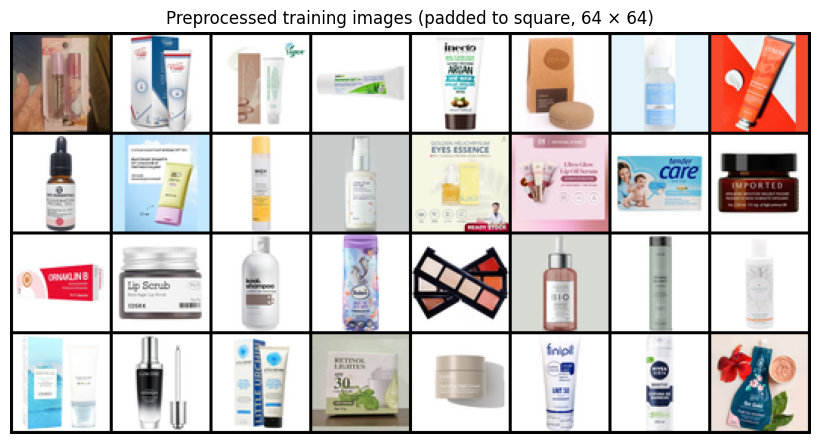

In [6]:
def to_square(img, size=IMAGE_SIZE):
    """Pad to a square with the image's own border colour (keeps aspect ratio), then resize."""
    img = img.convert("RGB")
    a = np.asarray(img)
    border = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    fill = tuple(int(v) for v in np.median(border, axis=0))
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), Image.Resampling.LANCZOS)

def load_tensor(files):
    arr = np.stack([np.asarray(to_square(Image.open(f)), dtype=np.uint8) for f in tqdm(files, desc="Preprocessing")])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(127.5).sub(1.0)     # [-1, 1]

X_train = load_tensor(train_files).to(device)
X_test = load_tensor(test_files).to(device)
print("Train tensor:", tuple(X_train.shape), "| Test tensor:", tuple(X_test.shape))

def batches(X, bs=BATCH_SIZE, shuffle=True, drop_last=True, gen=None):
    idx = torch.randperm(len(X), generator=gen, device="cpu") if shuffle else torch.arange(len(X))
    stop = len(X) - (len(X) % bs if drop_last else 0)
    for i in range(0, stop, bs):
        yield X[idx[i:i + bs].to(X.device)]

def show(t, title, path=None, nrow=8):
    g = make_grid((t[:64].detach().cpu() + 1) / 2, nrow=nrow).clamp(0, 1)
    if path: save_image(g, path)
    plt.figure(figsize=(nrow * 1.3, max(2, g.shape[1] / g.shape[2] * nrow * 1.3)))
    plt.imshow(g.permute(1, 2, 0)); plt.title(title); plt.axis("off"); plt.show()

show(X_train[:32], "Preprocessed training images (padded to square, 64 × 64)", RESULTS / "real_train_grid.png")

In [7]:
class Generator(nn.Module):
    def __init__(self, latent_dim=128, channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, channels, 4, 2, 1, bias=False), nn.Tanh())
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(channels, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Conv2d(256, 512, 4, 2, 1, bias=False), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, True),
            nn.Conv2d(512, 1, 4, 1, 0, bias=False))
    def forward(self, x): return self.net(x).view(-1)

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(True),
            nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(True))
        self.mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.logvar = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc = nn.Linear(latent_dim, 256 * 4 * 4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh())
    def encode(self, x):
        h = self.encoder(x).flatten(1); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
    def decode(self, z): return self.decoder(self.fc(z).view(-1, 256, 4, 4))
    def forward(self, x):
        mu, logvar = self.encode(x); return self.decode(self.reparameterize(mu, logvar)), mu, logvar

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

count = lambda m: sum(p.numel() for p in m.parameters())

In [8]:
# DiffAugment (Zhao et al., 2020): the same random, differentiable augmentation is applied to real AND
# generated images before the discriminator sees them, so D cannot simply memorise the 800 training images.
def diff_augment(x):
    b = x.size(0)
    # colour: brightness, saturation, contrast
    x = x + (torch.rand(b, 1, 1, 1, device=x.device) - 0.5)
    m = x.mean(1, keepdim=True); x = (x - m) * (torch.rand(b, 1, 1, 1, device=x.device) * 2) + m
    m = x.mean([1, 2, 3], keepdim=True); x = (x - m) * (torch.rand(b, 1, 1, 1, device=x.device) + 0.5) + m
    # translation up to 1/8 of the image, zero padded
    s = x.size(2) // 8
    tx, ty = torch.randint(-s, s + 1, (2, b), device=x.device)
    gy, gx = torch.meshgrid(torch.arange(x.size(2), device=x.device), torch.arange(x.size(3), device=x.device), indexing="ij")
    gx = (gx[None] + tx[:, None, None] + 1).clamp(0, x.size(3) + 1)
    gy = (gy[None] + ty[:, None, None] + 1).clamp(0, x.size(2) + 1)
    xp = F.pad(x, [1, 1, 1, 1])
    x = xp.permute(0, 2, 3, 1).contiguous()[torch.arange(b, device=x.device)[:, None, None], gy, gx].permute(0, 3, 1, 2)
    # cutout of half the image size
    cs = x.size(2) // 2
    ox, oy = torch.randint(0, x.size(3) + 1 - cs % 2, (2, b), device=x.device)
    yy, xx = torch.meshgrid(torch.arange(cs, device=x.device), torch.arange(cs, device=x.device), indexing="ij")
    yy = (yy[None] + oy[:, None, None] - cs // 2).clamp(0, x.size(2) - 1)
    xx = (xx[None] + ox[:, None, None] - cs // 2).clamp(0, x.size(3) - 1)
    mask = torch.ones(b, x.size(2), x.size(3), device=x.device)
    mask[torch.arange(b, device=x.device)[:, None, None], yy, xx] = 0
    return x * mask[:, None]

AUG = diff_augment if USE_DIFFAUGMENT else (lambda x: x)

In [9]:
set_seed(SEED)
G, D = Generator(LATENT_DIM).to(device), Discriminator().to(device)
G.apply(init_weights); D.apply(init_weights)
opt_G = torch.optim.Adam(G.parameters(), lr=LR_GAN, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR_GAN, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
gen = torch.Generator().manual_seed(SEED)
hist_gan = {k: [] for k in ["G", "D", "D_real_prob", "D_fake_prob", "D_acc", "seconds"]}

if device.type == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train(); s = dict(G=0, D=0, pr=0, pf=0, acc=0); n = 0; te = time.time()
    for real in batches(X_train, gen=gen):
        b = real.size(0)
        z = torch.randn(b, LATENT_DIM, 1, 1, device=device)
        fake = G(z)
        # discriminator
        opt_D.zero_grad(set_to_none=True)
        d_real, d_fake = D(AUG(real)), D(AUG(fake.detach()))
        d_loss = bce(d_real, torch.full_like(d_real, REAL_LABEL)) + bce(d_fake, torch.zeros_like(d_fake))
        d_loss.backward(); opt_D.step()
        # generator
        opt_G.zero_grad(set_to_none=True)
        out = D(AUG(fake))
        g_loss = bce(out, torch.ones_like(out))
        g_loss.backward(); opt_G.step()
        with torch.no_grad():
            pr, pf = torch.sigmoid(d_real), torch.sigmoid(d_fake)
            s["G"] += g_loss.item(); s["D"] += d_loss.item(); s["pr"] += pr.mean().item(); s["pf"] += pf.mean().item()
            s["acc"] += ((pr > 0.5).float().mean().item() + (pf < 0.5).float().mean().item()) / 2
        n += 1
    for k, key in [("G", "G"), ("D", "D"), ("pr", "D_real_prob"), ("pf", "D_fake_prob"), ("acc", "D_acc")]:
        hist_gan[key].append(s[k] / n)
    hist_gan["seconds"].append(time.time() - te)
    if epoch % PROGRESS_EVERY == 0 or epoch == 1:
        G.eval()
        with torch.no_grad(): save_image((G(fixed_noise) + 1) / 2, RESULTS / "progress" / f"dcgan_epoch{epoch:03d}.png", nrow=8)
        print(f"epoch {epoch:3d} | G {hist_gan['G'][-1]:.3f} | D {hist_gan['D'][-1]:.3f} | "
              f"D(x) {hist_gan['D_real_prob'][-1]:.2f} | D(G(z)) {hist_gan['D_fake_prob'][-1]:.2f} | D acc {hist_gan['D_acc'][-1]:.2f}")
if device.type == "cuda": torch.cuda.synchronize()
dcgan_seconds = time.time() - t0
dcgan_peak_gib = torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else float("nan")
print(f"DCGAN: {dcgan_seconds/60:.2f} min | {EPOCHS * (len(X_train) // BATCH_SIZE)} steps | peak GPU {dcgan_peak_gib:.2f} GiB")

epoch   1 | G 3.135 | D 0.816 | D(x) 0.76 | D(G(z)) 0.18 | D acc 0.87
epoch  25 | G 4.462 | D 0.400 | D(x) 0.87 | D(G(z)) 0.02 | D acc 0.99
epoch  50 | G 1.664 | D 1.125 | D(x) 0.58 | D(G(z)) 0.32 | D acc 0.74
epoch  75 | G 1.533 | D 1.338 | D(x) 0.53 | D(G(z)) 0.36 | D acc 0.63
epoch 100 | G 1.175 | D 1.288 | D(x) 0.53 | D(G(z)) 0.39 | D acc 0.65
epoch 125 | G 1.121 | D 1.383 | D(x) 0.52 | D(G(z)) 0.39 | D acc 0.62
epoch 150 | G 1.162 | D 1.193 | D(x) 0.56 | D(G(z)) 0.36 | D acc 0.71
epoch 175 | G 1.371 | D 1.250 | D(x) 0.54 | D(G(z)) 0.36 | D acc 0.66
epoch 200 | G 1.278 | D 1.182 | D(x) 0.56 | D(G(z)) 0.36 | D acc 0.70
epoch 225 | G 1.364 | D 1.169 | D(x) 0.56 | D(G(z)) 0.35 | D acc 0.72
epoch 250 | G 1.299 | D 1.267 | D(x) 0.52 | D(G(z)) 0.38 | D acc 0.64
epoch 275 | G 1.274 | D 1.181 | D(x) 0.55 | D(G(z)) 0.36 | D acc 0.71
epoch 300 | G 1.270 | D 1.168 | D(x) 0.55 | D(G(z)) 0.36 | D acc 0.70
DCGAN: 0.91 min | 3600 steps | peak GPU 0.33 GiB


In [10]:
set_seed(SEED)
vae = ConvVAE(LATENT_DIM).to(device)
opt_vae = torch.optim.Adam(vae.parameters(), lr=LR_VAE)
gen = torch.Generator().manual_seed(SEED)

def vae_loss(model, x):
    rec, mu, logvar = model(x)
    r = F.mse_loss(rec, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return r + BETA_KL * kl, r, kl

@torch.no_grad()
def vae_eval(model, X):
    model.eval(); tot = r = k = 0.0
    for x in batches(X, shuffle=False, drop_last=False):
        a, b, c = vae_loss(model, x); tot += a.item(); r += b.item(); k += c.item()
    return tot / len(X), r / len(X), k / len(X)

hist_vae = {k: [] for k in ["total", "reconstruction", "kl", "seconds", "test_epoch", "test_total", "test_reconstruction", "test_kl"]}
if device.type == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    vae.train(); tot = r = k = 0.0; te = time.time()
    for x in batches(X_train, gen=gen):
        opt_vae.zero_grad(set_to_none=True)
        loss, rl, kl = vae_loss(vae, x)
        loss.backward(); opt_vae.step()
        tot += loss.item(); r += rl.item(); k += kl.item()
    n_seen = (len(X_train) // BATCH_SIZE) * BATCH_SIZE
    hist_vae["total"].append(tot / n_seen); hist_vae["reconstruction"].append(r / n_seen); hist_vae["kl"].append(k / n_seen)
    hist_vae["seconds"].append(time.time() - te)
    if epoch % VAE_EVAL_EVERY == 0 or epoch == 1:
        a, b, c = vae_eval(vae, X_test)
        hist_vae["test_epoch"].append(epoch); hist_vae["test_total"].append(a); hist_vae["test_reconstruction"].append(b); hist_vae["test_kl"].append(c)
    if epoch % PROGRESS_EVERY == 0 or epoch == 1:
        vae.eval()
        with torch.no_grad(): save_image((vae.decode(fixed_noise.flatten(1)) + 1) / 2, RESULTS / "progress" / f"vae_epoch{epoch:03d}.png", nrow=8)
        print(f"epoch {epoch:3d} | train ELBO loss/img {hist_vae['total'][-1]:.1f} (recon {hist_vae['reconstruction'][-1]:.1f}, "
              f"KL {hist_vae['kl'][-1]:.1f}) | test loss/img {hist_vae['test_total'][-1]:.1f}")
if device.type == "cuda": torch.cuda.synchronize()
vae_seconds = time.time() - t0
vae_peak_gib = torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else float("nan")
print(f"VAE: {vae_seconds/60:.2f} min | peak GPU {vae_peak_gib:.2f} GiB")

epoch   1 | train ELBO loss/img 18613.2 (recon 5061.5, KL 13551.7) | test loss/img 3772.3
epoch  25 | train ELBO loss/img 709.0 (recon 614.6, KL 94.4) | test loss/img 807.6
epoch  50 | train ELBO loss/img 529.5 (recon 436.4, KL 93.1) | test loss/img 712.0
epoch  75 | train ELBO loss/img 447.5 (recon 356.0, KL 91.4) | test loss/img 695.1
epoch 100 | train ELBO loss/img 370.2 (recon 278.7, KL 91.5) | test loss/img 686.8
epoch 125 | train ELBO loss/img 330.6 (recon 241.7, KL 88.9) | test loss/img 686.0
epoch 150 | train ELBO loss/img 299.4 (recon 213.5, KL 85.9) | test loss/img 675.3
epoch 175 | train ELBO loss/img 285.1 (recon 199.4, KL 85.7) | test loss/img 691.1
epoch 200 | train ELBO loss/img 276.6 (recon 190.6, KL 86.0) | test loss/img 695.2
epoch 225 | train ELBO loss/img 262.2 (recon 179.8, KL 82.4) | test loss/img 703.7
epoch 250 | train ELBO loss/img 252.8 (recon 170.2, KL 82.6) | test loss/img 691.4
epoch 275 | train ELBO loss/img 246.6 (recon 165.4, KL 81.2) | test loss/img 707

Sampling speed: DCGAN 35,351 img/s | VAE 92,418 img/s


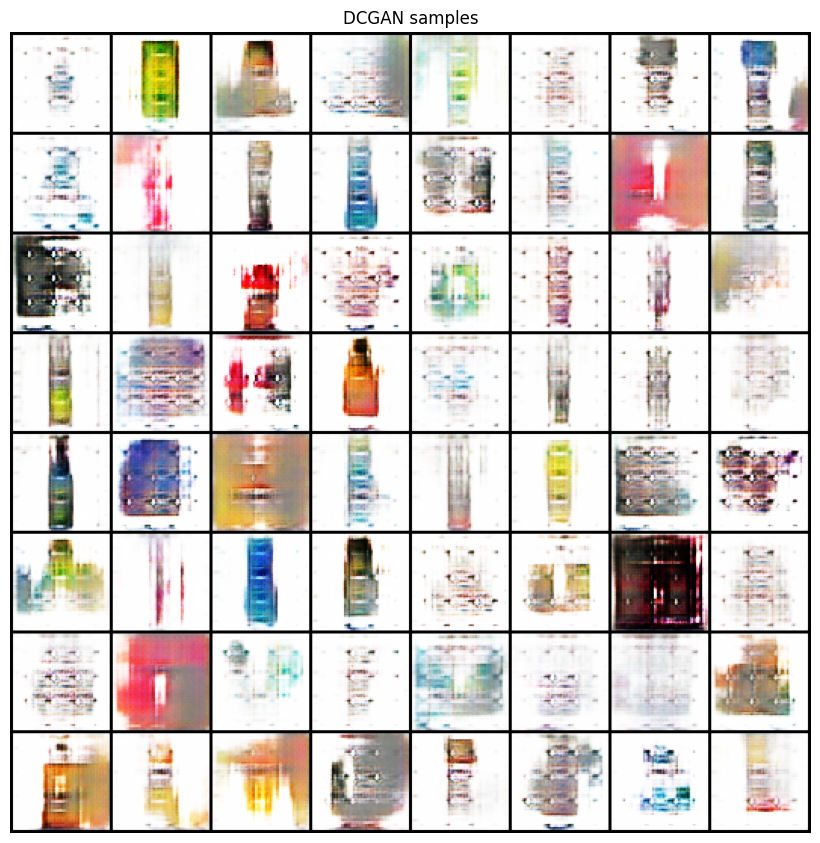

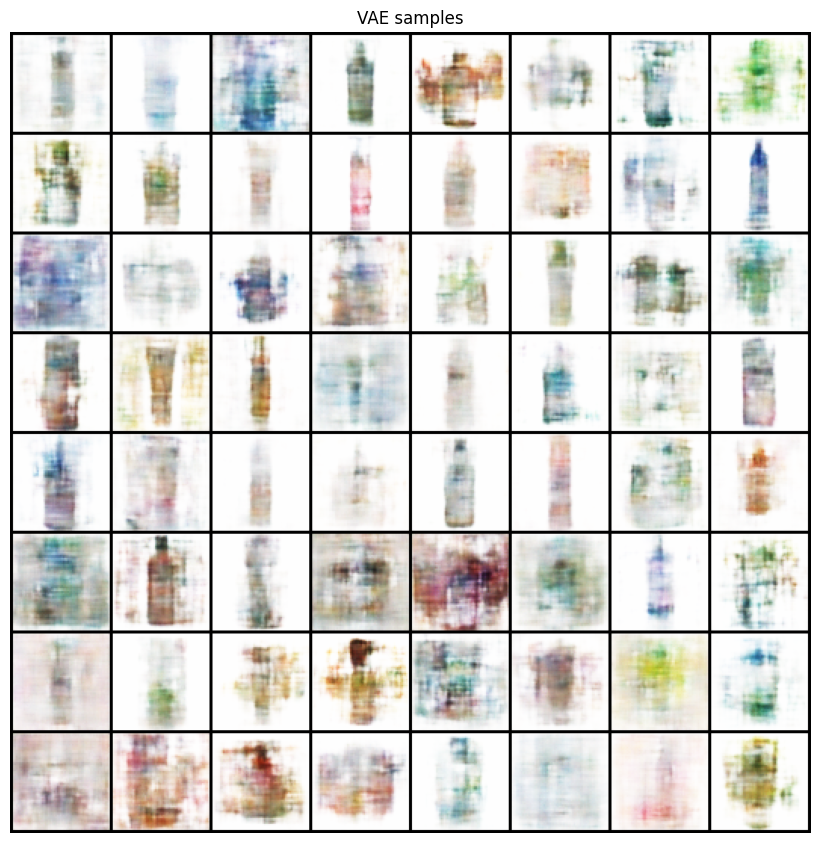

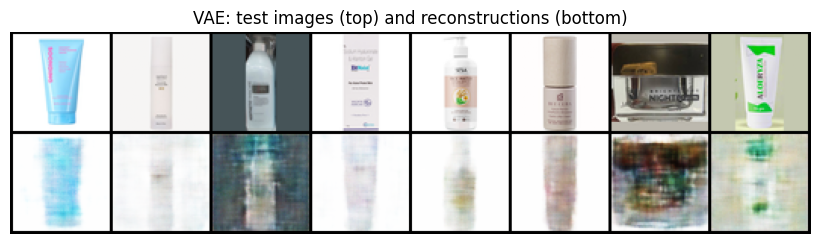

In [11]:
@torch.no_grad()
def sample(model_name, n, seed=SEED, bs=250):
    g = torch.Generator(device=device).manual_seed(seed); out = []
    for i in range(0, n, bs):
        m = min(bs, n - i)
        if model_name == "DCGAN":
            G.eval(); out.append(G(torch.randn(m, LATENT_DIM, 1, 1, device=device, generator=g)).clamp(-1, 1))
        else:
            vae.eval(); out.append(vae.decode(torch.randn(m, LATENT_DIM, device=device, generator=g)).clamp(-1, 1))
    return torch.cat(out)

def timed_sampling(name, n=N_EVAL_SAMPLES):
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time(); x = sample(name, n)
    if device.type == "cuda": torch.cuda.synchronize()
    return x, n / (time.time() - t)

gan_samples, gan_ips = timed_sampling("DCGAN")
vae_samples, vae_ips = timed_sampling("VAE")
print(f"Sampling speed: DCGAN {gan_ips:,.0f} img/s | VAE {vae_ips:,.0f} img/s")
show(gan_samples, "DCGAN samples", RESULTS / "dcgan_samples.png")
show(vae_samples, "VAE samples", RESULTS / "vae_samples.png")

with torch.no_grad():
    vae.eval(); rec, _, _ = vae(X_test[:8])
show(torch.cat([X_test[:8], rec]), "VAE: test images (top) and reconstructions (bottom)", RESULTS / "vae_reconstructions.png")

In [12]:
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn

to01 = lambda x: ((x + 1) / 2).clamp(0, 1)
def kid_fid(fake, real, subset=100):
    kid = KernelInceptionDistance(subset_size=min(subset, len(fake), len(real)), normalize=True).to(device)
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, is_real in ((real, True), (fake, False)):
        for i in range(0, len(x), 100):
            b = to01(x[i:i + 100]); kid.update(b, real=is_real); fid.update(b, real=is_real)
    km, ks = kid.compute()
    return km.item() * 1000, ks.item() * 1000, fid.compute().item()     # KID reported x 10^3

@torch.no_grad()
def mean_pairwise(x, n=200):
    f = x[:n].flatten(1); return torch.cdist(f, f).sum().item() / (len(f) * (len(f) - 1))

@torch.no_grad()
def nn_dist(a, ref):
    a, ref = a.flatten(1), ref.flatten(1)
    return torch.cat([torch.cdist(a[i:i + 250], ref).min(1).values for i in range(0, len(a), 250)])

ref_kid, ref_kid_sd, ref_fid = kid_fid(X_train, X_test)
real_div = mean_pairwise(X_test)
test_nn = nn_dist(X_test, X_train).mean().item()

rows = []
for name, xs, secs, peak, ips, m in [("DCGAN", gan_samples, dcgan_seconds, dcgan_peak_gib, gan_ips, G),
                                     ("VAE", vae_samples, vae_seconds, vae_peak_gib, vae_ips, vae)]:
    k, ksd, f = kid_fid(xs, X_test)
    rows.append({"model": name, "parameters": count(m) + (count(D) if name == "DCGAN" else 0),
                 "KID_x1e3_vs_test": k, "KID_sd_x1e3": ksd, "FID_vs_test": f,
                 "diversity_ratio": mean_pairwise(xs) / real_div,
                 "nn_train_distance_ratio": nn_dist(xs, X_train).mean().item() / test_nn,
                 "training_minutes": secs / 60, "peak_gpu_gib": peak, "sampling_img_per_s": ips})
rows.append({"model": "Real train vs test (reference)", "KID_x1e3_vs_test": ref_kid, "KID_sd_x1e3": ref_kid_sd,
             "FID_vs_test": ref_fid, "diversity_ratio": 1.0, "nn_train_distance_ratio": 1.0})
summary = pd.DataFrame(rows)

# VAE reconstruction quality on the test set
test_elbo, test_rec, test_kl = vae_eval(vae, X_test)
with torch.no_grad():
    vae.eval(); recs = torch.cat([vae(x)[0] for x in batches(X_test, shuffle=False, drop_last=False)])
mse = F.mse_loss(to01(recs), to01(X_test)).item()
vae_rec = {"test_loss_per_image": test_elbo, "test_recon_per_image": test_rec, "test_kl_per_image": test_kl,
           "test_pixel_mse_[-1,1]": F.mse_loss(recs, X_test).item(), "test_PSNR_dB": 10 * np.log10(1 / mse),
           "test_SSIM": ssim_fn(to01(recs), to01(X_test), data_range=1.0).item()}
display(summary.round(3)); print(json.dumps({k: round(v, 4) for k, v in vae_rec.items()}, indent=2))
summary.to_csv(RESULTS / "comparison_summary.csv", index=False)
(RESULTS / "vae_reconstruction_metrics.json").write_text(json.dumps(vae_rec, indent=2))

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 396MB/s]


,model,parameters,KID_x1e3_vs_test,KID_sd_x1e3,FID_vs_test,diversity_ratio,nn_train_distance_ratio,training_minutes,peak_gpu_gib,sampling_img_per_s
0,DCGAN,6571648.0,172.072,9.210,222.854,0.978,1.102,0.914,0.335,35350.819
1,VAE,2958595.0,200.038,8.640,232.164,0.601,0.747,0.385,0.285,92418.121
2,Real train vs test (reference),NaN,0.438,1.305,47.051,1.000,1.000,NaN,NaN,NaN


{
  "test_loss_per_image": 696.2402,
  "test_recon_per_image": 627.1652,
  "test_kl_per_image": 69.075,
  "test_pixel_mse_[-1,1]": 0.0516,
  "test_PSNR_dB": 18.8955,
  "test_SSIM": 0.6623
}


246

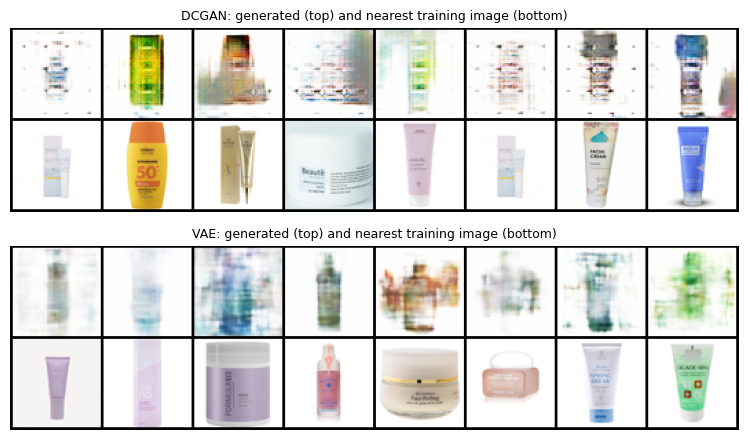

In [13]:
# Memorisation check: generated images next to their nearest training image
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5))
for ax, (name, xs) in zip(axes, [("DCGAN", gan_samples), ("VAE", vae_samples)]):
    q = xs[:8]
    idx = torch.cdist(q.flatten(1), X_train.flatten(1)).argmin(1)
    g = make_grid(to01(torch.cat([q, X_train[idx]])).cpu(), nrow=8)
    ax.imshow(g.permute(1, 2, 0)); ax.axis("off"); ax.set_title(f"{name}: generated (top) and nearest training image (bottom)", fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS / "nearest_neighbours.png", dpi=150); plt.show()

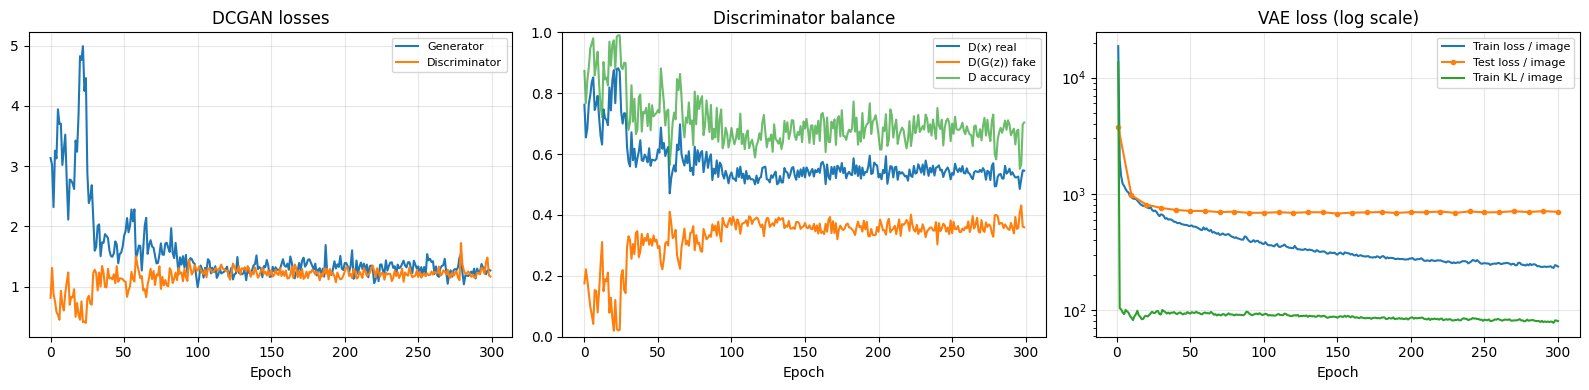

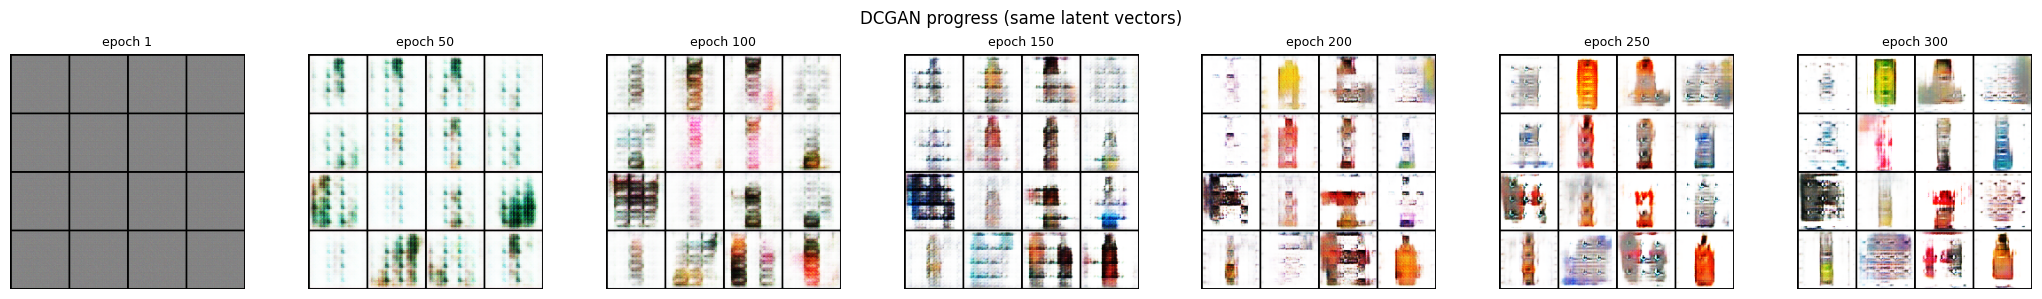

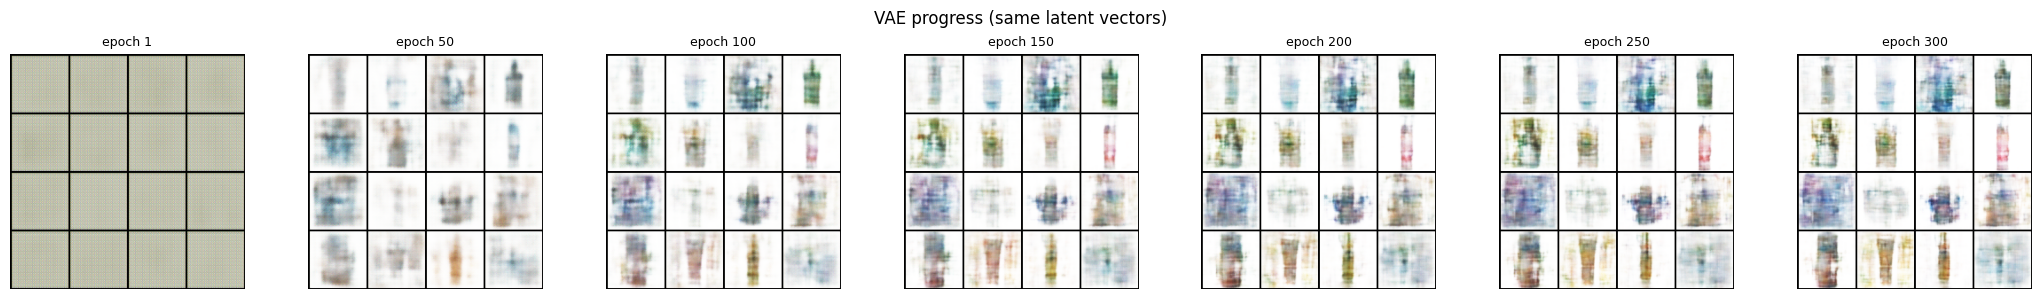

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist_gan["G"], label="Generator"); ax[0].plot(hist_gan["D"], label="Discriminator"); ax[0].set_title("DCGAN losses")
ax[1].plot(hist_gan["D_real_prob"], label="D(x) real"); ax[1].plot(hist_gan["D_fake_prob"], label="D(G(z)) fake")
ax[1].plot(hist_gan["D_acc"], label="D accuracy", alpha=0.7); ax[1].set_ylim(0, 1); ax[1].set_title("Discriminator balance")
ax[2].plot(range(1, EPOCHS + 1), hist_vae["total"], label="Train loss / image")
ax[2].plot(hist_vae["test_epoch"], hist_vae["test_total"], "o-", ms=3, label="Test loss / image")
ax[2].plot(range(1, EPOCHS + 1), hist_vae["kl"], label="Train KL / image"); ax[2].set_yscale("log"); ax[2].set_title("VAE loss (log scale)")
for a in ax: a.set_xlabel("Epoch"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS / "training_curves.png", dpi=160); plt.show()

# training progression
for name in ("dcgan", "vae"):
    eps = [1] + list(range(PROGRESS_EVERY, EPOCHS + 1, PROGRESS_EVERY))
    pick = [e for e in eps if (RESULTS / "progress" / f"{name}_epoch{e:03d}.png").exists()]
    pick = pick[:: max(1, len(pick) // 6)][:6] + ([pick[-1]] if pick[-1] not in pick[:: max(1, len(pick) // 6)][:6] else [])
    fig, axs = plt.subplots(1, len(pick), figsize=(3 * len(pick), 3))
    for a, e in zip(np.atleast_1d(axs), pick):
        im = Image.open(RESULTS / "progress" / f"{name}_epoch{e:03d}.png"); w, h = im.size
        a.imshow(im.crop((0, 0, w // 2, h // 2))); a.set_title(f"epoch {e}", fontsize=9); a.axis("off")
    plt.suptitle(f"{name.upper()} progress (same latent vectors)"); plt.tight_layout()
    plt.savefig(RESULTS / f"{name}_progress.png", dpi=130); plt.show()

In [15]:
import importlib.metadata as md_
torch.save(G.state_dict(), RESULTS / "dcgan_generator.pth")
torch.save(D.state_dict(), RESULTS / "dcgan_discriminator.pth")
torch.save(vae.state_dict(), RESULTS / "vae.pth")
(RESULTS / "training_history.json").write_text(json.dumps({"dcgan": hist_gan, "vae": hist_vae}))
(RESULTS / "split.json").write_text(json.dumps({"train": [str(p.relative_to(extract_dir)) for p in train_files],
                                               "test": [str(p.relative_to(extract_dir)) for p in test_files]}, indent=1))
ver = lambda p: (md_.version(p) if p else None)
meta = {
    "seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "steps_per_model": EPOCHS * (len(X_train) // BATCH_SIZE), "latent_dim": LATENT_DIM,
    "lr_gan": LR_GAN, "lr_vae": LR_VAE, "beta_kl": BETA_KL, "use_diffaugment": USE_DIFFAUGMENT, "real_label": REAL_LABEL,
    "preprocessing": "pad to square with median border colour, LANCZOS resize to 64x64, scale to [-1, 1]",
    "images": {"files": len(candidates), "valid_unique": len(unique), "exact_duplicates": exact_dups, "invalid": len(bad),
               "near_duplicate_pairs": int(len(pairs)), "groups": len(groups), "train": len(train_files),
               "test": len(test_files), "near_dup_pairs_crossing_split": int(cross)},
    "n_eval_samples": N_EVAL_SAMPLES, "kid_subset_size": 100,
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu", "python": platform.python_version(),
    "versions": {p: ver(p) for p in ["torch", "torchvision", "torchmetrics", "torch-fidelity", "numpy", "pillow"]},
}
(RESULTS / "metadata.json").write_text(json.dumps(meta, indent=2))
zip_path = shutil.make_archive(str(WORK / "cosmetics_model_results"), "zip", root_dir=RESULTS)
print("Created", zip_path)
try:
    from google.colab import files; files.download(zip_path)
except ImportError:
    pass

Created /content/cosmetics_model_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>